In [1]:
%load_ext autoreload
%autoreload 2
import emcee
import corner
import pickle
import time
from astropy.table import QTable
from astropy import units as u
from astropy import constants as const
import pandas as pd

from multiprocessing import Pool

import numpy as np
from matplotlib import pyplot as plt

from asymmetric_uncertainty_mod import a_u
from nfw_profile_heating import NFWProfile
from statistics_functions import chi_squared
from plotting import savefig, paper_plot
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
reflex_clean, variances = load_data_and_var()
reflex_clean.head()

/Users/eleanorstuart/Desktop/krisp/thermo-idm/load_data_and_var.py:14: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  low_z_data = comb_data[comb_data['z_y'] < 0.2][comb_data['Sub-Cat']=='REFLEX'][['OName',


,OName,Name,L500,z_y,MSZ,e_MSZ,E_MSZ,L_err
2,RXCJ0003.8+0203,A2700,0.846881,0.0924,2.238774,0.301448,0.282160,0.136707
3,RXCJ0006.0-3443,A2721,1.809494,0.1147,4.001657,0.226974,0.248869,0.211627
6,RXCJ0011.3-2851,A2734,1.086002,0.0620,2.606369,0.188038,0.182667,0.086428
9,RXCJ0013.6-1930,A0013,1.236332,0.0940,2.756623,0.245311,0.233331,0.124160
10,RXCJ0014.3-6604,A2746,2.827248,0.1599,3.030337,0.347930,0.328876,0.313974


In [8]:
nfws_werr = generate_nfws_from_combined_dataset_werr(reflex_clean, variances)

In [9]:
nfws= [nfw for nfw in nfws_werr if nfw.energies.is_virialized_gaspari]
len(nfws)

111

In [10]:
max([n.z for n in nfws])

0.1926

In [11]:
test_nfw = nfws[0]

In [12]:
test_rs = np.logspace(-3, 0)*test_nfw.R500
test_rs

array([<asymmetric_uncertainty_mod.core.a_u object at 0x12f0850d0>,
      dtype=object)

Text(0, 0.5, 'v (km/s)')

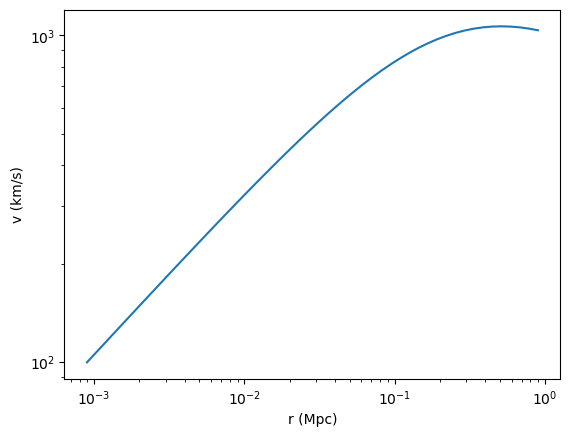

In [18]:
plt.loglog(test_rs, test_nfw.therm.velocity(test_rs))
plt.xlabel('r (Mpc)')
plt.ylabel('v (km/s)')

Text(0, 0.5, 'n_chi (1/Mpc3)')

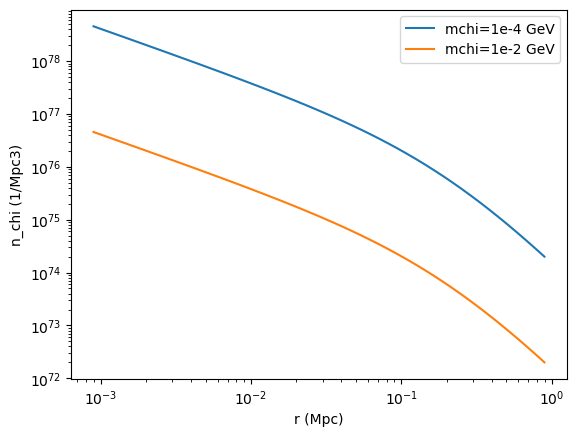

In [22]:
plt.loglog(test_rs, test_nfw.therm.dm_number_density(test_rs, 1e-4), label='mchi=1e-4 GeV')
plt.loglog(test_rs, test_nfw.therm.dm_number_density(test_rs, 1e-2), label='mchi=1e-2 GeV')
plt.legend()
plt.xlabel('r (Mpc)')
plt.ylabel('n_chi (1/Mpc3)')

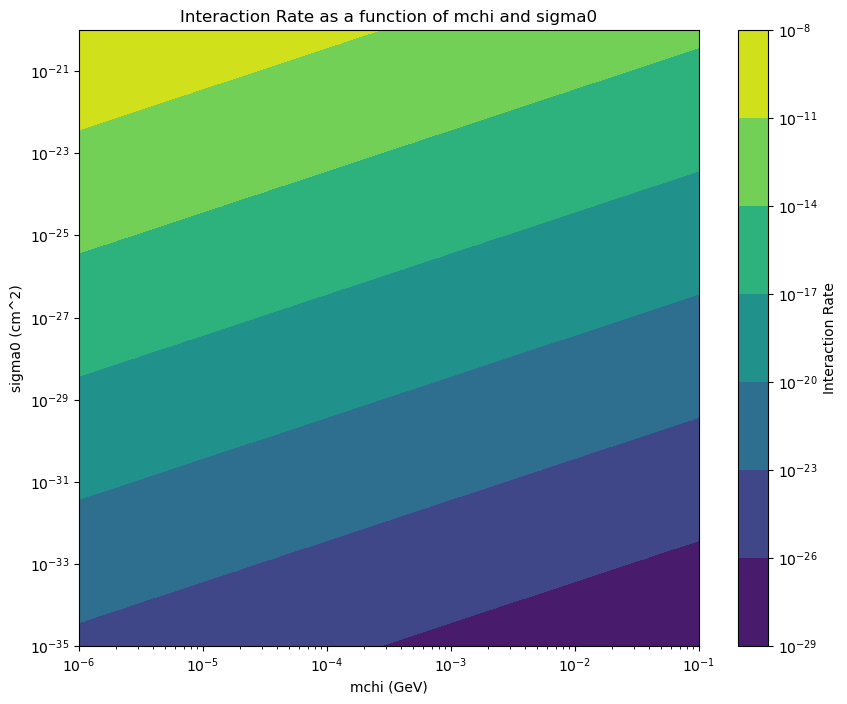

In [38]:
from matplotlib.colors import LogNorm

# Define the range of sigma0 and mchi values
sigma0_values = np.logspace(-35, -20, 50)  # Example range in cm^2
mchi_values = np.logspace(-6, -1, 50)       # Example range in GeV

# Create a meshgrid for sigma0 and mchi
sigma0_grid, mchi_grid = np.meshgrid(sigma0_values, mchi_values)

# Calculate the interaction rate for each combination of sigma0 and mchi
interaction_rate_grid = np.zeros_like(sigma0_grid)
for i in range(sigma0_grid.shape[0]):
    for j in range(sigma0_grid.shape[1]):
        sigma0 = sigma0_grid[i, j]
        mchi = mchi_grid[i, j]
        interaction_rate_grid[i, j] = test_nfw.therm.calculate_interaction_rate(sigma0, mchi)

# Plot the results
plt.figure(figsize=(10, 8))
cp = plt.contourf(mchi_grid, sigma0_grid, interaction_rate_grid, cmap='viridis', norm=LogNorm())
plt.colorbar(cp, label='Interaction Rate')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('mchi (GeV)')
plt.ylabel('sigma0 (cm^2)')
plt.title('Interaction Rate as a function of mchi and sigma0')
plt.show()

In [23]:
u.Mpc.to(u.cm)

3.085677581491367e+24

In [33]:
u.s.to(u.Gyr)

3.168808781402895e-17

In [35]:
(1/test_nfw.therm.calculate_interaction_rate(1e-4, 1e-27)).value/u.s.to(u.Gyr)

1.1821134628533041e-12